<a href="https://colab.research.google.com/github/kevinketerlondon-tech/Data-Analyst-portfolio/blob/main/02_change_detection_and_equity_(4).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 02: Same-spot vegetation change detection and deprivation analysis
**Kevin Keter · University of East London**

Detects street-level vegetation change from repeat Mapillary imagery using only comparable same-spot photo pairs,
and relates the change to the English Indices of Deprivation 2025.

| Output | Section |
|---|---|
| Comparability check of the earlier tile-based change pairs | 3 |
| Same-spot pair selection, vegetation measurement and change classification | 4–6 |
| Borough/LSOA lookup and IMD 2025 join | 7 |
| Change summary, model agreement and exploratory deprivation analysis | 8 |
| Before/after figures with change maps, location maps and plots | 9 |


**What "comparable pair" means here** (all must hold):
* both photos within **15 m** of each other,
* the **same camera type** (normal, 360° or fisheye),
* for normal/fisheye cameras, facing within **30°** of the same direction,
* both taken in the **leaf-on season (May–September)** and within **2 calendar months** of each other,
* at least **3 years** apart,
* and the two photos must visibly show **the same view**: static structures (road, kerbs, buildings, poles) match
  geometrically and the camera tilt is similar (Section 6). Thresholds are calibrated on a manually labelled sample of 40 pairs.

## 1. Settings

In [ ]:
import os, sys, glob, json, time, math, random, shutil, re, io, getpass, platform
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd

IN_COLAB = "google.colab" in sys.modules

CFG = dict(
    drive_dir   = "/content/drive/MyDrive/Dissertation/revision",
    work_dir    = "/content/work",
    checkpoint  = "nvidia/segformer-b0-finetuned-cityscapes-1024-1024",
    veg_class   = 8,
    long_side   = 1024,
    # The two study boxes used in the dissertation. Key names are kept from the dissertation code;
    # the real borough of every location is looked up from its postcode in Section 7.
    areas       = {"southwark": [-0.13, 51.49, -0.10, 51.52], "newham": [-0.045, 51.51, -0.015, 51.54]},
    # names used in tables and figures (the boxes were mislabelled in the dissertation; real boroughs come from postcodes)
    area_labels = {"southwark": "Central London", "newham": "East London"},
    tile_deg_original = 0.006,       # dissertation tile size (used to map the original 35 locations)
    fetch_tile_deg    = 0.003,       # Mapillary query tile; split further automatically if a tile is too dense
    max_dist_m        = 15.0,
    max_heading_deg   = 30.0,
    leaf_on_months    = [5, 6, 7, 8, 9],
    max_month_gap     = 2,
    min_year_gap      = 3,
    min_location_spacing_m = 50.0,   # selected locations are at least this far apart (independence)
    min_capture_year  = 2013,        # Mapillary launched in 2013; earlier capture dates are camera-clock errors
    pairs_per_location = 5,          # best pair + 4 alternatives at the same spot
    max_candidate_locations_per_area = 500,
    max_locations_per_area = 400,
    # same-view check thresholds, calibrated on 40 manually labelled pairs (view_check_calibration_labels.csv):
    # 30 inliers / 0.15 passed no pair the rater rejected but missed 49% of good pairs; 15 / 0.20 keeps 72% and still passes none the rater rejected
    view_min_inliers  = 15,          # matched static features (fundamental-matrix RANSAC inliers)
    view_max_ground_diff = 0.20,     # max difference in road+pavement share of the frame (camera tilt)
    near_training_m   = 100.0,       # flag locations within this distance of an annotated training image
    imd_url = "https://assets.publishing.service.gov.uk/media/691ded56d140bbbaa59a2a7d/File_7_IoD2025_All_Ranks_Scores_Deciles_Population_Denominators.csv",
    n_bootstrap = 10000,
    n_examples_each = 4,             # before/after figure: LOSS and GAIN examples
)
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

DRIVE, WORK = CFG["drive_dir"], CFG["work_dir"]
R1  = os.path.join(DRIVE, "results_v3")              # Notebook 01 outputs
OUT = os.path.join(DRIVE, "results_change_v3")
CACHE = os.path.join(OUT, "cache")
for d in [WORK, OUT, CACHE, f"{CACHE}/images", f"{OUT}/tables", f"{OUT}/figures"]:
    os.makedirs(d, exist_ok=True)
assert os.path.exists(f"{R1}/SUMMARY.json"), "Run Notebook 01 to the end first (results_v3/SUMMARY.json is missing)."

import requests
import torch, torch.nn as nn, torch.nn.functional as F
from transformers import SegformerForSemanticSegmentation
from PIL import Image
from scipy import stats
from scipy.spatial import cKDTree
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TOKEN = os.environ.get("MAPILLARY_TOKEN") or getpass.getpass("Mapillary token: ")
json.dump({k: v for k, v in CFG.items()}, open(f"{OUT}/config.json", "w"), indent=2, default=str)

Mounted at /content/drive
Mapillary token: ··········


## 2. Fetch every Mapillary image in the two study boxes (cached on Drive)

In [ ]:
FIELDS = "id,captured_at,computed_geometry,geometry,compass_angle,computed_compass_angle,camera_type,sequence"
API = "https://graph.mapillary.com"

def api_get(url, params, tries=4):
    for k in range(tries):
        try:
            r = requests.get(url, params=params, timeout=60)
            if r.status_code == 200:
                return r
            if r.status_code in (400, 404):
                return r
        except requests.RequestException:
            pass
        time.sleep(2 * (k + 1))
    return None

def fetch_bbox(bbox, depth=0):
    """All images in bbox. Dense boxes (HTTP 500 or a full page) are split into 4 and fetched recursively."""
    r = api_get(f"{API}/images", {"access_token": TOKEN, "fields": FIELDS, "limit": 2000, "bbox": ",".join(map(str, bbox))})
    data = r.json().get("data", []) if (r is not None and r.status_code == 200) else None
    if (data is None or len(data) >= 2000) and depth < 6:
        x0, y0, x1, y1 = bbox; xm, ym = (x0 + x1) / 2, (y0 + y1) / 2
        out = []
        for b in [[x0, y0, xm, ym], [xm, y0, x1, ym], [x0, ym, xm, y1], [xm, ym, x1, y1]]:
            out += fetch_bbox(b, depth + 1)
        return out
    return data or []

def tiles(box, step):
    x0, y0, x1, y1 = box; out = []
    y = y0
    while y < y1 - 1e-12:
        x = x0
        while x < x1 - 1e-12:
            out.append([x, y, min(x + step, x1), min(y + step, y1)]); x += step
        y += step
    return out

def to_rows(items, area):
    rows = []
    for d in items:
        g = d.get("computed_geometry") or d.get("geometry")
        if not g or d.get("captured_at") is None:
            continue
        rows.append(dict(image_id=str(d["id"]), area=area, lng=g["coordinates"][0], lat=g["coordinates"][1],
                         captured_at=pd.to_datetime(d["captured_at"], unit="ms", utc=True),
                         heading=d.get("computed_compass_angle", d.get("compass_angle")),
                         camera_type=d.get("camera_type") or "unknown", sequence=d.get("sequence", "")))
    return rows

def fetch_area(area, box):
    path = f"{CACHE}/mapillary_{area}.csv"
    if os.path.exists(path):
        df = pd.read_csv(path, dtype={"image_id": str, "sequence": str})
        df["captured_at"] = pd.to_datetime(df.captured_at, utc=True, format="ISO8601")
        return df
    T = tiles(box, CFG["fetch_tile_deg"]); items = []
    for i, t in enumerate(T):
        items += fetch_bbox(t)
        if (i + 1) % 25 == 0: print(f"  {area}: {i + 1}/{len(T)} tiles, {len(items)} images")
        time.sleep(0.05)
    df = pd.DataFrame(to_rows(items, area)).drop_duplicates("image_id")
    df.to_csv(path, index=False)
    return df

IMGS = pd.concat([fetch_area(a, b) for a, b in CFG["areas"].items()], ignore_index=True)
IMGS["captured_at"] = pd.to_datetime(IMGS.captured_at, utc=True, format="ISO8601")
IMGS["year"], IMGS["month"] = IMGS.captured_at.dt.year, IMGS.captured_at.dt.month
print(IMGS.groupby("area").agg(images=("image_id", "size"), sequences=("sequence", "nunique"),
                               first=("year", "min"), last=("year", "max")))
print(IMGS.camera_type.value_counts())

           images  sequences  first  last
area                                     
newham      29762        283   2014  2026
southwark   81492       1305   2004  2026
camera_type
perspective        92121
spherical          15329
fisheye             2802
equirectangular      973
unknown               29
Name: count, dtype: int64


## 3. Comparability check of the 35 earlier change pairs
Each original "location" was a whole ~500 m tile, and the code compared the first photo of the earliest year
with the first photo of the latest year anywhere in that tile. This cell measures each pair.

In [ ]:
ORIG = pd.read_csv(f"{DRIVE}/original35_pairs.csv", dtype={"earliest_image": str, "latest_image": str})
need = sorted(set(ORIG.earliest_image) | set(ORIG.latest_image))
known = IMGS.set_index("image_id")
meta = pd.read_csv(f"{DRIVE}/mapillary_metadata_312.csv", dtype={"image_id": str}).set_index("image_id")

def image_meta(iid):
    if iid in known.index:
        r = known.loc[iid]; return dict(lat=r.lat, lng=r.lng, heading=r.heading, camera=r.camera_type, t=pd.Timestamp(r.captured_at))
    if iid in meta.index:
        r = meta.loc[iid]; return dict(lat=r.lat, lng=r.lng, heading=r.compass_angle, camera=r.camera_type, t=pd.Timestamp(r.captured_at))
    r = api_get(f"{API}/{iid}", {"access_token": TOKEN, "fields": FIELDS})
    if r is None or r.status_code != 200: return None
    row = to_rows([r.json()], "x")
    if not row: return None
    row = row[0]; return dict(lat=row["lat"], lng=row["lng"], heading=row["heading"], camera=row["camera_type"], t=row["captured_at"])

def hav(lat1, lng1, lat2, lng2):
    p1, p2, dl = np.radians(lat1), np.radians(lat2), np.radians(np.asarray(lng2) - np.asarray(lng1))
    return 6371000 * 2 * np.arcsin(np.sqrt(np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2))

def angdiff(a, b):
    return np.abs((np.asarray(a) - np.asarray(b) + 180) % 360 - 180)

def month_gap(a, b):
    d = np.abs(np.asarray(a) - np.asarray(b)); return np.minimum(d, 12 - d)

rows = []
for r in ORIG.itertuples():
    a, b = image_meta(r.earliest_image), image_meta(r.latest_image)
    if a is None or b is None:
        rows.append(dict(area=r.area, tile=r.cluster_id, years=f"{r.earliest_year}->{r.latest_year}", old_change_pp=r.change_pct_points,
                         old_direction=r.direction, verdict="NOT VERIFIABLE", issues="image no longer on Mapillary")); continue
    d = float(hav(a["lat"], a["lng"], b["lat"], b["lng"])); hd = float(angdiff(a["heading"], b["heading"]))
    mg = int(month_gap(a["t"].month, b["t"].month)); issues = []
    if d > CFG["max_dist_m"]: issues.append(f"{d:.0f} m apart")
    if a["camera"] != b["camera"]: issues.append(f"camera {a['camera']} vs {b['camera']}")
    elif a["camera"] != "spherical" and hd > CFG["max_heading_deg"]: issues.append(f"facing {hd:.0f}° apart")
    if mg > CFG["max_month_gap"]: issues.append(f"months {a['t'].month}/{b['t'].month}")
    if not (a["t"].month in CFG["leaf_on_months"] and b["t"].month in CFG["leaf_on_months"]): issues.append("leaf-off season")
    rows.append(dict(area=r.area, tile=r.cluster_id, years=f"{r.earliest_year}->{r.latest_year}", old_change_pp=r.change_pct_points,
                     old_direction=r.direction, distance_m=round(d, 1), heading_diff_deg=round(hd), months=f"{a['t'].month}/{b['t'].month}",
                     cameras=f"{a['camera']}/{b['camera']}", verdict="COMPARABLE" if not issues else "NOT COMPARABLE", issues="; ".join(issues)))
T_ORIG = pd.DataFrame(rows)
T_ORIG.to_csv(f"{OUT}/tables/T_original35_pair_review.csv", index=False)
print(T_ORIG.verdict.value_counts().to_string())
print(f"Median distance between 'before' and 'after' photo: {T_ORIG.distance_m.median():.0f} m; "
      f">15 m: {(T_ORIG.distance_m > 15).sum()}, >100 m: {(T_ORIG.distance_m > 100).sum()}; "
      f"camera type mismatch: {(T_ORIG.cameras.str.split('/').str[0] != T_ORIG.cameras.str.split('/').str[1]).sum()}")
print(T_ORIG.to_string(index=False))

verdict
NOT COMPARABLE    34
NOT VERIFIABLE     1
Median distance between 'before' and 'after' photo: 26 m; >15 m: 23, >100 m: 10; camera type mismatch: 12
     area  tile      years  old_change_pp old_direction  distance_m  heading_diff_deg months                 cameras        verdict                                                                     issues
   newham     0 2017->2026          -14.4          LOSS        26.2             178.0    6/4 perspective/perspective NOT COMPARABLE                             26 m apart; facing 178° apart; leaf-off season
   newham     3 2015->2022          -15.4          LOSS        22.6              43.0    9/6 perspective/perspective NOT COMPARABLE                                   23 m apart; facing 43° apart; months 9/6
   newham     7 2018->2025           15.9          GAIN        15.2             102.0    4/6   perspective/spherical NOT COMPARABLE               15 m apart; camera perspective vs spherical; leaf-off season
   newham     8 

## 4. Candidate same-spot pairs (metadata rules)
Every candidate location keeps its best pair plus up to four alternative pairs at the same spot,
so that a location is not lost if its first pair fails the visual same-view check in Section 6.

In [ ]:
def build_candidates(df):
    lat0, lng0 = df.lat.mean(), df.lng.mean()
    xy = np.c_[(df.lng - lng0) * 111320 * math.cos(math.radians(lat0)), (df.lat - lat0) * 110574]
    funnel = [("Images with location and date", len(df))]
    keep = (df.year >= CFG["min_capture_year"]).to_numpy().copy()
    funnel.append((f"...dated {CFG['min_capture_year']} or later (earlier dates are camera-clock errors)", int(keep.sum())))
    keep = keep & df.month.isin(CFG["leaf_on_months"]).to_numpy()
    funnel.append(("...taken in leaf-on months (May-Sep)", int(keep.sum())))
    d = df[keep].reset_index(drop=True); P = xy[keep]
    if len(d) < 2:
        return pd.DataFrame(), funnel
    ij = cKDTree(P).query_pairs(r=CFG["max_dist_m"], output_type="ndarray")
    funnel.append((f"Photo pairs within {CFG['max_dist_m']:g} m", len(ij)))
    yi, yj = d.year.values[ij[:, 0]], d.year.values[ij[:, 1]]
    ij = ij[np.abs(yi - yj) >= CFG["min_year_gap"]]
    funnel.append((f"...at least {CFG['min_year_gap']} years apart", len(ij)))
    ij = ij[d.camera_type.values[ij[:, 0]] == d.camera_type.values[ij[:, 1]]]
    funnel.append(("...same camera type", len(ij)))
    hd = angdiff(d.heading.values[ij[:, 0]], d.heading.values[ij[:, 1]])
    sph = d.camera_type.values[ij[:, 0]] == "spherical"
    ok = sph | (np.nan_to_num(hd, nan=999) <= CFG["max_heading_deg"])
    ij, hd = ij[ok], hd[ok]
    funnel.append((f"...facing within {CFG['max_heading_deg']:g}° (360° cameras exempt)", len(ij)))
    mg = month_gap(d.month.values[ij[:, 0]], d.month.values[ij[:, 1]])
    ok = mg <= CFG["max_month_gap"]
    ij, hd, mg = ij[ok], hd[ok], mg[ok]
    funnel.append((f"...within {CFG['max_month_gap']} calendar months", len(ij)))
    if not len(ij):
        return pd.DataFrame(), funnel
    early = np.where(d.year.values[ij[:, 0]] <= d.year.values[ij[:, 1]], ij[:, 0], ij[:, 1])
    late = np.where(early == ij[:, 0], ij[:, 1], ij[:, 0])
    pr = pd.DataFrame(dict(before=d.image_id.values[early], after=d.image_id.values[late],
                           before_date=d.captured_at.values[early], after_date=d.captured_at.values[late],
                           year_gap=d.year.values[late] - d.year.values[early],
                           distance_m=np.hypot(*(P[early] - P[late]).T),
                           heading_diff=np.where(d.camera_type.values[early] == "spherical", np.nan, hd),
                           month_gap=mg, camera_type=d.camera_type.values[early],
                           lat=(d.lat.values[early] + d.lat.values[late]) / 2, lng=(d.lng.values[early] + d.lng.values[late]) / 2,
                           x=(P[early, 0] + P[late, 0]) / 2, y=(P[early, 1] + P[late, 1]) / 2))
    # best pair first: longest time span, then closest, then best-aligned, then closest in season
    pr = pr.sort_values(["year_gap", "distance_m", "heading_diff", "month_gap"], ascending=[False, True, True, True],
                        na_position="first").reset_index(drop=True)
    centres, cand = np.empty((0, 2)), []          # cand[k] = list of pair row indices for location k (best first)
    for r in pr.itertuples():
        if len(centres):
            dist = np.hypot(centres[:, 0] - r.x, centres[:, 1] - r.y); k = int(dist.argmin())
            if dist[k] < CFG["min_location_spacing_m"]:
                if dist[k] <= CFG["max_dist_m"] and len(cand[k]) < CFG["pairs_per_location"]:
                    cand[k].append(r.Index)       # alternative pair at the same spot
                continue
        if len(cand) >= CFG["max_candidate_locations_per_area"]:
            continue
        centres = np.vstack([centres, [r.x, r.y]]); cand.append([r.Index])
    rows = []
    for k, idx in enumerate(cand):
        for rank, i in enumerate(idx):
            rows.append(dict(cand_location=k, pair_rank=rank, **pr.loc[i].drop(["x", "y"]).to_dict()))
    funnel.append((f"Candidate locations (>= {CFG['min_location_spacing_m']:g} m apart, up to {CFG['pairs_per_location']} pairs each)", len(cand)))
    return pd.DataFrame(rows), funnel

CANDS, FUN = [], []
for area in CFG["areas"]:
    c, funnel = build_candidates(IMGS[IMGS.area == area])
    if len(c): c.insert(0, "area", area); CANDS.append(c)
    FUN += [dict(area=area, step=s, count=c_) for s, c_ in funnel]
CANDS = pd.concat(CANDS, ignore_index=True)
print(pd.DataFrame(FUN).pivot(index="step", columns="area", values="count").reindex(pd.DataFrame(FUN).step.unique()).to_string())

area                                                            newham  southwark
step                                                                             
Images with location and date                                    29762      81492
...dated 2013 or later (earlier dates are camera-clock errors)   29762      80950
...taken in leaf-on months (May-Sep)                             19473      62239
Photo pairs within 15 m                                         797964    2881909
...at least 3 years apart                                        31717     447877
...same camera type                                              12891     256916
...facing within 30° (360° cameras exempt)                        4690      90107
...within 2 calendar months                                       2778      85920
Candidate locations (>= 50 m apart, up to 5 pairs each)             34        239


## 5. Models (exactly as trained in Notebook 01) and photo download

In [ ]:
CITYSCAPES = ["road", "sidewalk", "building", "wall", "fence", "pole", "traffic light", "traffic sign", "vegetation", "terrain",
              "sky", "person", "rider", "car", "truck", "bus", "train", "motorcycle", "bicycle"]
STATIC_CLASSES = [0, 1, 2, 3, 4, 5, 6, 7]      # road ... traffic sign: things that stay put between visits
GROUND_CLASSES = [0, 1]                         # road, sidewalk (their share of the frame reveals camera tilt)
MEAN = np.array([0.485, 0.456, 0.406], np.float32); STD = np.array([0.229, 0.224, 0.225], np.float32)

def load_base_model():
    return SegformerForSemanticSegmentation.from_pretrained(CFG["checkpoint"])

def encoder_layers(model):
    out = []
    for name, m in model.segformer.named_modules():
        if type(m).__name__ == "SegformerLayer":
            nums = re.findall(r"\d+", name); out.append((int(nums[-2]), int(nums[-1]), m))
    return sorted(out, key=lambda t: (t[0], t[1]))

class BottleneckAdapter(nn.Module):
    def __init__(self, dim, b):
        super().__init__(); self.down_project = nn.Linear(dim, b); self.activation = nn.GELU(); self.up_project = nn.Linear(b, dim)
    def forward(self, x): return x + self.up_project(self.activation(self.down_project(x)))

def build(spec):
    model = load_base_model()
    if spec["method"] == "adapter":
        model.adapters = nn.ModuleDict()
        for s, b, layer in encoder_layers(model):
            ln = getattr(layer, "layernorm_after", None) or getattr(layer, "layer_norm_2")
            key = f"stage{s}_block{b}"; model.adapters[key] = BottleneckAdapter(ln.weight.shape[0], spec["bottleneck"])
            ln.register_forward_hook(lambda mod, i, o, a=model.adapters[key]: a(o))
    return model

SUMMARY1 = json.load(open(f"{R1}/SUMMARY.json"))
LR = SUMMARY1["chosen_lr"]
def runs_for(method):
    if method == "zeroshot":
        return [json.load(open(f"{R1}/runs/zeroshot_full/metrics.json"))]
    out = []
    for p in glob.glob(f"{R1}/runs/{method}*_full/metrics.json"):
        r = json.load(open(p)); s = r["spec"]
        if s["lr"] == LR[method] and (method != "adapter" or s["bottleneck"] == 32):
            out.append(r)
    return sorted(out, key=lambda r: r["spec"]["seed"])

MODELS = {m: runs_for(m) for m in ["zeroshot", "adapter", "full"]}
MODELS = {m: rs for m, rs in MODELS.items() if rs}
print({m: [r["run_id"] for r in rs] for m, rs in MODELS.items()})

def prep(path):
    im = Image.open(path).convert("RGB")
    s = CFG["long_side"] / max(im.size)
    im = im.resize((max(1, round(im.size[0] * s)), max(1, round(im.size[1] * s))), Image.BILINEAR)
    a = np.asarray(im)
    x = torch.from_numpy(((a.astype(np.float32) / 255 - MEAN) / STD).transpose(2, 0, 1).copy())[None]
    return a, x

def download(iid):
    path = f"{CACHE}/images/{iid}.jpg"
    if os.path.exists(path) and os.path.getsize(path) > 1000:
        return path
    r = api_get(f"{API}/{iid}", {"access_token": TOKEN, "fields": "thumb_1024_url"})
    url = r.json().get("thumb_1024_url") if (r is not None and r.status_code == 200) else None
    if not url: return None
    for k in range(3):
        try:
            b = requests.get(url, timeout=60)
            if b.status_code == 200 and len(b.content) > 1000:
                open(path, "wb").write(b.content); return path
        except requests.RequestException:
            time.sleep(2)
    return None

paths = {}
def fetch_all(ids):
    ids = [i for i in ids if not paths.get(i)]
    with ThreadPoolExecutor(8) as ex:
        paths.update(dict(zip(ids, ex.map(download, ids))))

{'zeroshot': ['zeroshot_full'], 'adapter': ['adapter_b32_lr0.003_s0_full', 'adapter_b32_lr0.003_s1_full', 'adapter_b32_lr0.003_s2_full'], 'full': ['full_lr0.0001_s0_full', 'full_lr0.0001_s1_full', 'full_lr0.0001_s2_full']}


## 6. Same-view check
GPS and compass cannot detect a camera that is tilted, zoomed or blocked differently. Each candidate pair is therefore
checked visually: (a) SIFT features on **static structures only** (road, kerb, buildings, walls, poles, signs; vegetation,
sky and vehicles are masked out) must match under a geometric model (fundamental matrix, RANSAC), and
(b) the share of the frame covered by road + pavement must be similar (a strong cue for camera tilt).
For each location the best-ranked pair that passes is kept.

In [ ]:
import cv2
SEG_DIR = f"{CACHE}/classmaps"; os.makedirs(SEG_DIR, exist_ok=True)
ZS_MODEL = build(dict(method="zeroshot")).to(DEVICE).eval()

@torch.no_grad()
def classmap(iid):
    p = f"{SEG_DIR}/{iid}.npy"
    if os.path.exists(p): return np.load(p)
    a, x = prep(paths[iid])
    lg = F.interpolate(ZS_MODEL(pixel_values=x.to(DEVICE)).logits, size=x.shape[-2:], mode="bilinear", align_corners=False)[0]
    c = lg.argmax(0).cpu().numpy().astype(np.uint8); np.save(p, c); return c

SIFT = cv2.SIFT_create(nfeatures=4000)
def view_check(b, a):
    A, _ = prep(paths[b]); B, _ = prep(paths[a]); ca, cb = classmap(b), classmap(a)
    ground_diff = abs(np.isin(ca, GROUND_CLASSES).mean() - np.isin(cb, GROUND_CLASSES).mean())
    m1 = cv2.dilate(np.isin(ca, STATIC_CLASSES).astype(np.uint8) * 255, np.ones((5, 5), np.uint8))
    m2 = cv2.dilate(np.isin(cb, STATIC_CLASSES).astype(np.uint8) * 255, np.ones((5, 5), np.uint8))
    k1, d1 = SIFT.detectAndCompute(cv2.cvtColor(A, cv2.COLOR_RGB2GRAY), m1)
    k2, d2 = SIFT.detectAndCompute(cv2.cvtColor(B, cv2.COLOR_RGB2GRAY), m2)
    inl, H = 0, None
    if d1 is not None and d2 is not None and len(k1) >= 8 and len(k2) >= 8:
        good = [m for m, n in (p for p in cv2.BFMatcher(cv2.NORM_L2).knnMatch(d2, d1, k=2) if len(p) == 2) if m.distance < 0.75 * n.distance]
        if len(good) >= 8:
            src = np.float32([k2[m.queryIdx].pt for m in good]); dst = np.float32([k1[m.trainIdx].pt for m in good])
            Fm, mask = cv2.findFundamentalMat(src, dst, cv2.FM_RANSAC, 3.0, 0.99)
            inl = int(mask.sum()) if mask is not None else 0
            Hm, hmask = cv2.findHomography(src, dst, cv2.RANSAC, 8.0)
            if Hm is not None and hmask is not None and hmask.sum() >= 30: H = Hm.tolist()
    passed = inl >= CFG["view_min_inliers"] and ground_diff <= CFG["view_max_ground_diff"]
    return dict(inliers=inl, ground_diff=round(float(ground_diff), 4), view_ok=bool(passed), H=json.dumps(H))

VC_PATH = f"{CACHE}/view_checks.csv"
VC = pd.read_csv(VC_PATH, dtype={"before": str, "after": str}) if os.path.exists(VC_PATH) else pd.DataFrame(columns=["before", "after"])
def apply_thresholds(v):          # verdict always recomputed from the stored scores, so changing a threshold never needs re-matching
    if len(v): v["view_ok"] = (v.inliers.astype(float) >= CFG["view_min_inliers"]) & (v.ground_diff.astype(float) <= CFG["view_max_ground_diff"])
    return v
VC = apply_thresholds(VC)
done = set(zip(VC.before, VC.after))
resolved = set()
for rank in range(CFG["pairs_per_location"]):        # try the best pair at every spot, then the 2nd, then the 3rd
    rows = CANDS[(CANDS.pair_rank == rank) & ~CANDS.apply(lambda r: (r.area, r.cand_location) in resolved, axis=1)]
    if not len(rows): break
    fetch_all(sorted(set(rows.before) | set(rows.after)))
    new = []
    for r in rows.itertuples():
        if not (paths.get(r.before) and paths.get(r.after)): continue
        if (r.before, r.after) not in done:
            new.append(dict(before=r.before, after=r.after, **view_check(r.before, r.after))); done.add((r.before, r.after))
    if new:
        VC = apply_thresholds(pd.concat([VC, pd.DataFrame(new)], ignore_index=True)); VC.to_csv(VC_PATH, index=False)
    ok = rows.merge(VC, on=["before", "after"])
    resolved |= set(zip(ok[ok.view_ok.astype(bool)].area, ok[ok.view_ok.astype(bool)].cand_location))
    print(f"pair rank {rank + 1}: checked {len(ok)} pairs, locations resolved so far: {len(resolved)}")

CHK = CANDS.merge(VC, on=["before", "after"], how="inner")
CHK["view_ok"] = CHK.view_ok.astype(bool)
LOCS = (CHK[CHK.view_ok].sort_values(["area", "cand_location", "pair_rank"]).groupby(["area", "cand_location"]).head(1)
        .groupby("area", group_keys=False).head(CFG["max_locations_per_area"]).reset_index(drop=True))
for area in CFG["areas"]:
    FUN.append(dict(area=area, step=f"...passing the same-view check (best of up to {CFG['pairs_per_location']} pairs per spot)", count=int((LOCS.area == area).sum())))
T_FUNNEL = pd.DataFrame(FUN); T_FUNNEL["area"] = T_FUNNEL.area.map(CFG["area_labels"]); T_FUNNEL.to_csv(f"{OUT}/tables/T_change_pair_funnel.csv", index=False)
print(T_FUNNEL.pivot(index="step", columns="area", values="count").reindex(T_FUNNEL.step.unique()).to_string())
if not len(LOCS):
    raise SystemExit("No location passed the same-view check - see the funnel table above.")
LOCS.insert(0, "location_id", [f"{a[:1].upper()}{i:03d}" for i, a in enumerate(LOCS.area)])
LOCS.insert(2, "area_label", LOCS.area.map(CFG["area_labels"]))
for area, lab in CFG["area_labels"].items():
    n_ = int((LOCS.area == area).sum())
    if n_ < 20: print(f"NOTE: only {n_} comparable locations in {lab} - results for this area will be very uncertain.")

# Threshold calibration on the first manually labelled sample (kept for the paper)
CAL_PATH = f"{DRIVE}/view_check_calibration_labels.csv"
CAL = pd.read_csv(CAL_PATH, dtype={"before": str, "after": str}) if os.path.exists(CAL_PATH) else None
if CAL is not None:
    hy = CAL.human_same_view.astype(bool); rows = []
    for mi in [10, 15, 20, 25, 30]:
        for gd in [0.15, 0.20, 0.25]:
            p_ = (CAL.inliers >= mi) & (CAL.ground_diff <= gd)
            rows.append(dict(min_inliers=mi, max_ground_diff=gd, pairs_passed=int(p_.sum()), passed_but_rater_said_different=int((p_ & ~hy).sum()),
                             share_of_rater_same_view_pairs_kept=round((p_ & hy).sum() / max(1, hy.sum()), 3),
                             chosen=(mi == CFG["view_min_inliers"] and gd == CFG["view_max_ground_diff"])))
    pd.DataFrame(rows).to_csv(f"{OUT}/tables/T_view_check_threshold_calibration.csv", index=False)

fetch_all(sorted(set(LOCS.before) | set(LOCS.after)))   # make sure every photo used below is loaded (some checks come from the cache)

# how many of the 35 original tiles contain at least one comparable location now?
def tile_index(area, lat, lng):
    for k, t in enumerate(tiles(CFG["areas"][area], CFG["tile_deg_original"])):
        if t[0] <= lng < t[2] and t[1] <= lat < t[3]:
            return k
    return -1
LOCS["original_tile"] = [tile_index(r.area, r.lat, r.lng) for r in LOCS.itertuples()]
covered = ORIG.apply(lambda r: ((LOCS.area == r.area) & (LOCS.original_tile == r.cluster_id)).any(), axis=1)
print(f"\nOriginal 35 tiles that now have at least one comparable same-spot pair: {covered.sum()}/35")

SPLIT = pd.read_csv(f"{DRIVE}/split_v3_grouped.csv", dtype={"image_id": str})
tr = SPLIT[SPLIT.new_split == "train"]
LOCS["dist_to_training_image_m"] = [float(hav(r.lat, r.lng, tr.lat.values, tr.lng.values).min()) for r in LOCS.itertuples()]
LOCS["near_training"] = LOCS.dist_to_training_image_m < CFG["near_training_m"]

config.json:   0%|          | 0.00/1.68k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 15.0MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.9MB            

model.safetensors: downloading bytes:           |  0.00B            

pair rank 1: checked 272 pairs, locations resolved so far: 77
pair rank 2: checked 186 pairs, locations resolved so far: 96
pair rank 3: checked 163 pairs, locations resolved so far: 107
pair rank 4: checked 148 pairs, locations resolved so far: 110
pair rank 5: checked 136 pairs, locations resolved so far: 119
area                                                             Central London  East London
step                                                                                        
Images with location and date                                             81492        29762
...dated 2013 or later (earlier dates are camera-clock errors)            80950        29762
...taken in leaf-on months (May-Sep)                                      62239        19473
Photo pairs within 15 m                                                 2881909       797964
...at least 3 years apart                                                447877        31717
...same camera type                 

## 7. Measure vegetation cover with each model (decision rules exactly as in Notebook 01)

In [ ]:
ids = sorted(set(LOCS.before) | set(LOCS.after))
fetch_all(ids)
PRED_PATH = f"{CACHE}/predictions.csv"
PRED = pd.read_csv(PRED_PATH, dtype={"image_id": str}) if os.path.exists(PRED_PATH) else pd.DataFrame(columns=["image_id"])
MASK_DIR = f"{CACHE}/masks"; os.makedirs(MASK_DIR, exist_ok=True)
todo = [i for i in ids if i not in set(PRED.image_id) or not os.path.exists(f"{MASK_DIR}/{i}_shape.npy")]
PRED = PRED[~PRED.image_id.isin(todo)]      # drop stale rows (e.g. from an earlier version of this notebook)
if todo:
    new = {i: {"image_id": i} for i in todo}
    for m, rs in MODELS.items():
        for r in rs:
            seed = r["spec"].get("seed", 0)
            model = build(r["spec"])
            if m != "zeroshot":
                model.load_state_dict(torch.load(f"{R1}/runs/{r['run_id']}/best.pt", map_location="cpu"), strict=False)
            model.to(DEVICE).eval()
            with torch.no_grad():
                for i in todo:
                    a, x = prep(paths[i])
                    lg = F.interpolate(model(pixel_values=x.to(DEVICE)).logits, size=x.shape[-2:], mode="bilinear", align_corners=False)[0]
                    mask = (lg.argmax(0) == CFG["veg_class"]) if m == "zeroshot" else (torch.sigmoid(lg[CFG["veg_class"]]) > 0.5)
                    new[i][f"veg_pct_{m}_s{seed}"] = 100 * mask.float().mean().item()
                    np.save(f"{MASK_DIR}/{i}_{m}_s{seed}.npy", np.packbits(mask.cpu().numpy()))
                    np.save(f"{MASK_DIR}/{i}_shape.npy", np.array(mask.shape))
            del model
    PRED = pd.concat([PRED, pd.DataFrame(new.values())], ignore_index=True)
    PRED.to_csv(PRED_PATH, index=False)
for m in MODELS:
    PRED[f"veg_pct_{m}"] = PRED[[c for c in PRED.columns if c.startswith(f"veg_pct_{m}_s")]].mean(axis=1)

def load_mask(iid, m):
    shape = tuple(np.load(f"{MASK_DIR}/{iid}_shape.npy"))
    ms = [np.unpackbits(np.load(f), count=int(np.prod(shape))).reshape(shape) for f in sorted(glob.glob(f"{MASK_DIR}/{iid}_{m}_s*.npy"))]
    return np.mean(ms, axis=0) > 0.5                                  # majority vote over seeds

def homography(r):
    H = json.loads(r.H) if isinstance(r.H, str) else None
    return np.array(H) if H else None


# change per location and the measurement-noise threshold from Notebook 01's test-set errors
P = PRED.set_index("image_id")
TAU = {}
for m in MODELS:
    LOCS[f"before_pct_{m}"] = LOCS.before.map(P[f"veg_pct_{m}"]); LOCS[f"after_pct_{m}"] = LOCS.after.map(P[f"veg_pct_{m}"])
    LOCS[f"change_pp_{m}"] = LOCS[f"after_pct_{m}"] - LOCS[f"before_pct_{m}"]
    pi = pd.read_csv(f"{R1}/tables/T_per_image_test_iou.csv")
    err = pi[f"pred_pct_{m}"] - pi.gt_pct
    TAU[m] = float(1.96 * math.sqrt(2) * err.std(ddof=1))         # 95% band for the difference of two independent measurements
    LOCS[f"direction_{m}"] = np.select([LOCS[f"change_pp_{m}"] <= -TAU[m], LOCS[f"change_pp_{m}"] >= TAU[m]], ["LOSS", "GAIN"], "STABLE")
    LOCS[f"direction_1pp_{m}"] = np.select([LOCS[f"change_pp_{m}"] < -1, LOCS[f"change_pp_{m}"] > 1], ["LOSS", "GAIN"], "STABLE")
PRIMARY = "adapter" if "adapter" in MODELS else list(MODELS)[0]
print("Change threshold tau (pp) per model, from test-set measurement error:", {k: round(v, 2) for k, v in TAU.items()})

Change threshold tau (pp) per model, from test-set measurement error: {'zeroshot': 13.45, 'adapter': 10.08, 'full': 9.04}


## 8. Real borough and LSOA of every location, joined to IMD 2025

In [ ]:
def geo_key(lat, lng):
    return f"{lat:.6f},{lng:.6f}"

def reverse_geocode(df):
    """Borough + LSOA (2021) of each location from its nearest postcode. Cached by coordinates, not by location id."""
    path = f"{CACHE}/geocode_by_coord.csv"
    have = pd.read_csv(path, dtype={"geo_key": str}) if os.path.exists(path) else pd.DataFrame(columns=["geo_key"])
    keys = df.apply(lambda r: geo_key(r.lat, r.lng), axis=1)
    need = ~keys.isin(set(have.geo_key))
    todo = df.loc[need].copy(); todo["geo_key"] = keys[need].values
    rows = []
    for k in range(0, len(todo), 100):
        chunk = todo.iloc[k:k + 100]
        body = {"geolocations": [{"longitude": r.lng, "latitude": r.lat, "radius": 500, "limit": 1} for r in chunk.itertuples()]}
        res = requests.post("https://api.postcodes.io/postcodes", json=body, timeout=60).json()["result"]
        for r, q in zip(chunk.itertuples(), res):
            hit = (q.get("result") or [None])[0]
            rows.append(dict(geo_key=r.geo_key, lsoa21=(hit or {}).get("codes", {}).get("lsoa"), lsoa_name=(hit or {}).get("lsoa"),
                             borough=(hit or {}).get("admin_district"), postcode=(hit or {}).get("postcode"),
                             postcode_distance_m=(hit or {}).get("distance")))
        time.sleep(0.2)
    have = pd.concat([have, pd.DataFrame(rows)], ignore_index=True).drop_duplicates("geo_key")
    have.to_csv(path, index=False)
    return have

LOCS["geo_key"] = LOCS.apply(lambda r: geo_key(r.lat, r.lng), axis=1)
GEO = reverse_geocode(LOCS)
LOCS = LOCS.drop(columns=[c for c in ["lsoa21", "lsoa_name", "borough", "postcode", "postcode_distance_m"] if c in LOCS]).merge(GEO, on="geo_key", how="left")

def load_imd():
    path = f"{CACHE}/IoD2025_File7.csv"
    if not os.path.exists(path):
        r = requests.get(CFG["imd_url"], timeout=120); r.raise_for_status(); open(path, "wb").write(r.content)
    imd = pd.read_csv(path, encoding="latin-1")
    code = [c for c in imd.columns if "LSOA" in c.upper() and "CODE" in c.upper()][0]
    score = [c for c in imd.columns if "Index of Multiple Deprivation" in c and "Score" in c][0]
    decile = [c for c in imd.columns if "Index of Multiple Deprivation" in c and "Decile" in c][0]
    return imd[[code, score, decile]].rename(columns={code: "lsoa21", score: "imd_score", decile: "imd_decile"})

IMD = load_imd()
LOCS = LOCS.drop(columns=[c for c in ["imd_score", "imd_decile"] if c in LOCS]).merge(IMD, on="lsoa21", how="left")
print(f"Locations matched to an LSOA: {LOCS.lsoa21.notna().sum()}/{len(LOCS)}; matched to IMD 2025: {LOCS.imd_score.notna().sum()}/{len(LOCS)}")
print("\nReal boroughs inside each dissertation study box:")
print(LOCS.groupby(["area", "borough"]).size().rename("locations").to_string())
LOCS.to_csv(f"{OUT}/tables/T_change_locations.csv", index=False)

Locations matched to an LSOA: 119/119; matched to IMD 2025: 119/119

Real boroughs inside each dissertation study box:
area       borough       
newham     Tower Hamlets      9
southwark  Camden            16
           City of London    12
           Lambeth           29
           Southwark         15
           Westminster       38


## 9. Change summary, model agreement and equity (preliminary)

In [ ]:
def boot_ci(x, f=np.mean, n=None):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    if len(x) < 3: return (np.nan, np.nan)
    rng = np.random.default_rng(0); n = n or CFG["n_bootstrap"]
    b = [f(rng.choice(x, len(x))) for _ in range(n)]
    return (float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5)))

def summary_rows(groupcol):
    out = []
    for g, d in LOCS.groupby(groupcol):
        for m in MODELS:
            ch = d[f"change_pp_{m}"]; lo, hi = boot_ci(ch)
            vc = d[f"direction_{m}"].value_counts()
            out.append(dict(group_by=groupcol, group=g, model=m, n_locations=len(d), mean_change_pp=ch.mean(), ci95_low=lo, ci95_high=hi,
                            median_change_pp=ch.median(), LOSS=int(vc.get("LOSS", 0)), GAIN=int(vc.get("GAIN", 0)), STABLE=int(vc.get("STABLE", 0)),
                            tau_pp=TAU[m], wilcoxon_p_vs_zero=float(stats.wilcoxon(ch.dropna()).pvalue) if (ch.dropna() != 0).sum() > 5 else np.nan))
    return out

LOCS["all"] = "all locations"
T_SUM = pd.DataFrame(summary_rows("all") + summary_rows("area_label") + summary_rows("borough"))
T_SUM.to_csv(f"{OUT}/tables/T_change_summary.csv", index=False)
print(T_SUM.round(3).to_string(index=False))

# robustness: change measured only inside the area visible in BOTH photos (after homography alignment)
import cv2
def overlap_change(r, m):
    H = homography(r)
    if H is None: return np.nan
    ma, mb = load_mask(r.before, m), load_mask(r.after, m)
    wb = cv2.warpPerspective(mb.astype(np.uint8), H, (ma.shape[1], ma.shape[0]), flags=cv2.INTER_NEAREST).astype(bool)
    valid = cv2.warpPerspective(np.ones(mb.shape, np.uint8), H, (ma.shape[1], ma.shape[0]), flags=cv2.INTER_NEAREST).astype(bool)
    if valid.mean() < 0.3: return np.nan                      # too little overlap to be meaningful
    return 100 * (wb[valid].mean() - ma[valid].mean())
for m in MODELS:
    LOCS[f"change_overlap_pp_{m}"] = [overlap_change(r, m) for r in LOCS.itertuples()]

# robustness: excluding locations near annotated training images; and the dissertation's +/-1 pp rule
rob = []
for name, d in [("all", LOCS), ("excluding locations < 100 m from a training image", LOCS[~LOCS.near_training])]:
    for m in MODELS:
        vc = d[f"direction_{m}"].value_counts(); vc1 = d[f"direction_1pp_{m}"].value_counts()
        rob.append(dict(subset=name, model=m, n=len(d), mean_change_pp=d[f"change_pp_{m}"].mean(),
                        LOSS=vc.get("LOSS", 0), GAIN=vc.get("GAIN", 0), STABLE=vc.get("STABLE", 0),
                        LOSS_1pp_rule=vc1.get("LOSS", 0), GAIN_1pp_rule=vc1.get("GAIN", 0), STABLE_1pp_rule=vc1.get("STABLE", 0),
                        n_with_overlap_estimate=int(d[f"change_overlap_pp_{m}"].notna().sum()),
                        mean_change_overlap_only_pp=d[f"change_overlap_pp_{m}"].mean(),
                        spearman_whole_vs_overlap=d[[f"change_pp_{m}", f"change_overlap_pp_{m}"]].dropna().corr("spearman").iloc[0, 1]
                                                  if d[f"change_overlap_pp_{m}"].notna().sum() > 3 else np.nan))
T_ROB = pd.DataFrame(rob); T_ROB.to_csv(f"{OUT}/tables/T_change_robustness.csv", index=False)
print("\nROBUSTNESS"); print(T_ROB.round(3).to_string(index=False))

# agreement between models on the direction of change
ag = []
ms = list(MODELS)
for i, a in enumerate(ms):
    for b in ms[i + 1:]:
        same = (LOCS[f"direction_{a}"] == LOCS[f"direction_{b}"]).mean()
        r = stats.spearmanr(LOCS[f"change_pp_{a}"], LOCS[f"change_pp_{b}"]).statistic if len(LOCS) > 2 else np.nan
        ag.append(dict(model_a=a, model_b=b, same_direction_pct=100 * same, spearman_change=r))
T_AGREE = pd.DataFrame(ag); T_AGREE.to_csv(f"{OUT}/tables/T_model_agreement.csv", index=False)
print("\nMODEL AGREEMENT"); print(T_AGREE.round(3).to_string(index=False))

# equity: vegetation change vs deprivation (PRELIMINARY: observational, small n, spatially clustered)
def required_n(r, alpha=0.05, power=0.8):
    if not r or np.isnan(r) or abs(r) < 1e-6: return np.inf
    z = stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)
    return int(math.ceil((z / math.atanh(abs(r))) ** 2 + 3))

eq = []
E = LOCS.dropna(subset=["imd_score"])
for m in MODELS:
    for level, d in [("location", E), ("LSOA mean (removes repeated LSOAs)", E.groupby("lsoa21").agg(imd_score=("imd_score", "first"), **{f"change_pp_{m}": (f"change_pp_{m}", "mean")}).reset_index())]:
        if len(d) < 4: continue
        x, y = d.imd_score.values, d[f"change_pp_{m}"].values
        pr, pp = stats.pearsonr(x, y); sr, sp = stats.spearmanr(x, y)
        rng = np.random.default_rng(0); bs = []
        for _ in range(CFG["n_bootstrap"]):
            k = rng.integers(0, len(x), len(x))
            if np.std(x[k]) > 0 and np.std(y[k]) > 0: bs.append(stats.spearmanr(x[k], y[k]).statistic)
        eq.append(dict(model=m, level=level, n=len(d), pearson_r=pr, pearson_p=pp, spearman_rho=sr, spearman_p=sp,
                       spearman_ci95_low=np.percentile(bs, 2.5), spearman_ci95_high=np.percentile(bs, 97.5),
                       n_needed_for_80pct_power=required_n(sr)))
T_EQ = pd.DataFrame(eq); T_EQ.to_csv(f"{OUT}/tables/T_equity_correlations.csv", index=False)
print("\nEQUITY (preliminary)"); print(T_EQ.round(3).to_string(index=False))
if len(E):
    E2 = E.assign(imd_group=pd.cut(E.imd_decile, [0, 3, 7, 10], labels=["most deprived (deciles 1-3)", "middle (4-7)", "least deprived (8-10)"]))
    T_EQG = E2.groupby("imd_group", observed=True)[f"change_pp_{PRIMARY}"].agg(["count", "mean", "median", "std"]).reset_index()
    T_EQG.to_csv(f"{OUT}/tables/T_equity_by_imd_group.csv", index=False); print(T_EQG.round(3).to_string(index=False))

  group_by          group    model  n_locations  mean_change_pp  ci95_low  ci95_high  median_change_pp  LOSS  GAIN  STABLE  tau_pp  wilcoxon_p_vs_zero
       all  all locations zeroshot          119           1.186    -0.299      2.670             0.147     5    10     104  13.446               0.049
       all  all locations  adapter          119           1.321    -0.077      2.746             0.187     8    16      95  10.078               0.020
       all  all locations     full          119           1.471     0.076      2.873             0.190     9    18      92   9.039               0.012
area_label Central London zeroshot          110           1.073    -0.472      2.637             0.211     5     8      97  13.446               0.057
area_label Central London  adapter          110           1.174    -0.270      2.640             0.168     7    14      89  10.078               0.038
area_label Central London     full          110           1.333    -0.110      2.792          

## 10. Figures (300 dpi PNG + PDF in `results_change_v3/figures/`)

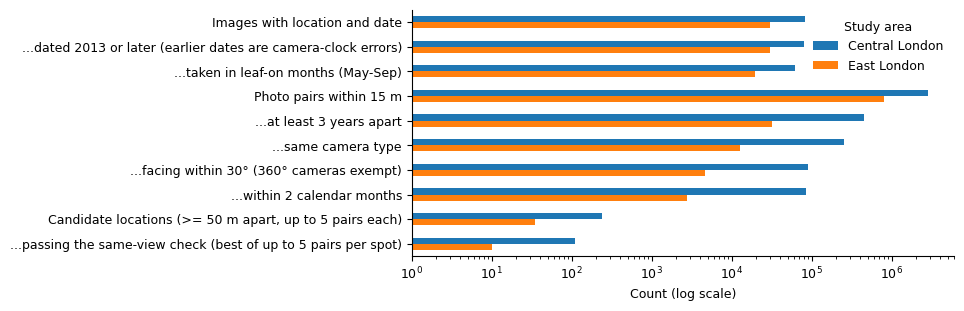

LOSS examples: 1 (pixel-aligned: 1)
GAIN examples: 3 (pixel-aligned: 3)
STABLE examples: 2 (pixel-aligned: 2)


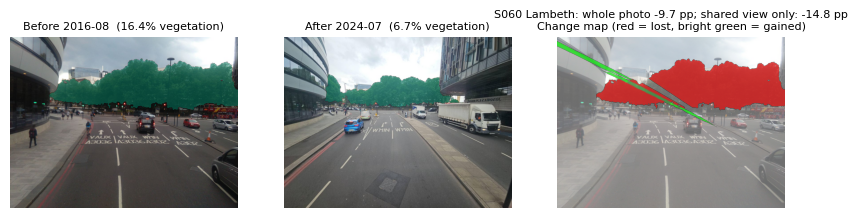

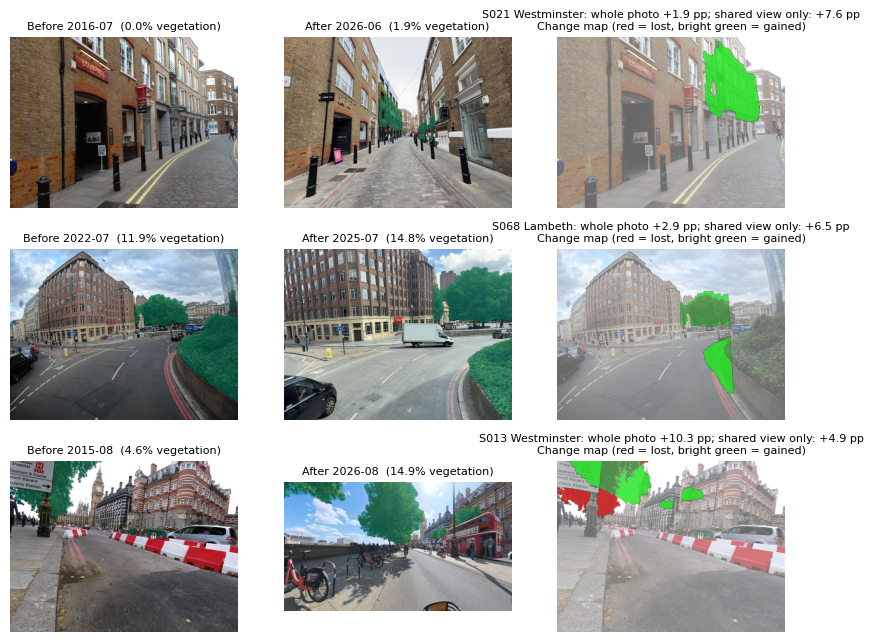

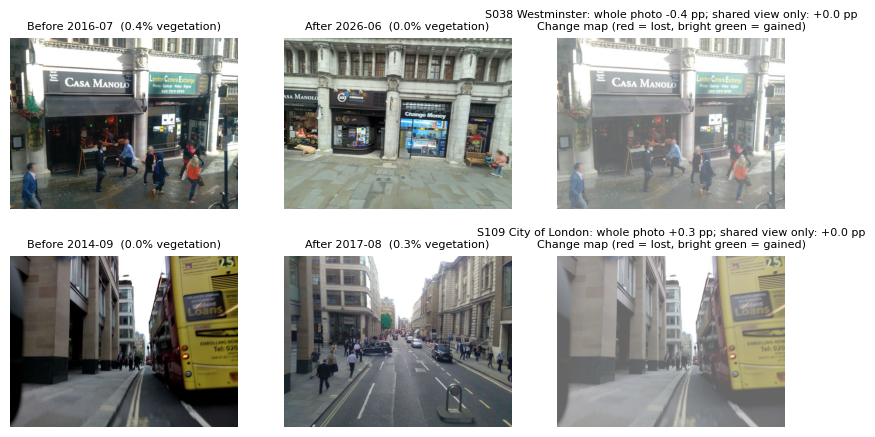

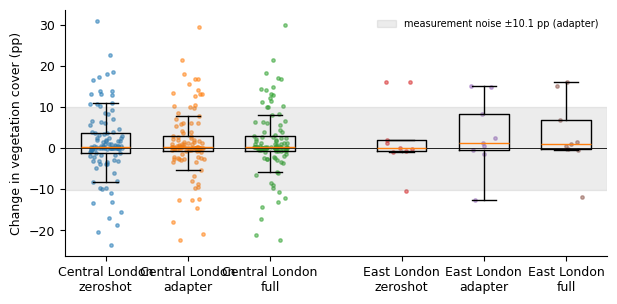

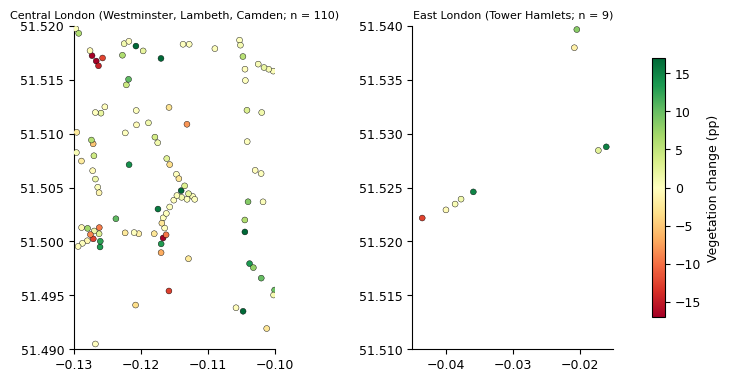

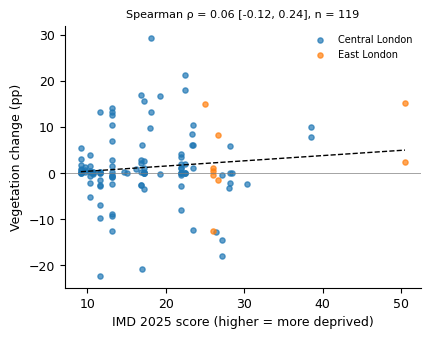

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

DONE


In [ ]:
import matplotlib
if not IN_COLAB: matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    for ext in ["png", "pdf"]: fig.savefig(f"{OUT}/figures/{name}.{ext}", dpi=300, bbox_inches="tight")
    if IN_COLAB: plt.show()
    plt.close(fig)

# F1: pair funnel
fig, ax = plt.subplots(figsize=(7, 3.2))
piv = T_FUNNEL.pivot(index="step", columns="area", values="count").reindex(T_FUNNEL.step.unique())
piv.plot.barh(ax=ax, log=True, color=["#1f77b4", "#ff7f0e"]); ax.invert_yaxis(); ax.set_xlabel("Count (log scale)"); ax.set_ylabel("")
ax.legend(title="Study area", frameon=False)
save(fig, "F_change_pair_funnel")

# F2: before/after examples with a pixel change map (photos aligned with the homography from the same-view check)
def example_figure(rows, name):
    if not len(rows): return
    fig, ax = plt.subplots(len(rows), 3, figsize=(10, 2.6 * len(rows)))
    ax = np.atleast_2d(ax)
    for i, r in enumerate(rows.itertuples()):
        A, _ = prep(paths[r.before]); B, _ = prep(paths[r.after])
        ma, mb = load_mask(r.before, PRIMARY), load_mask(r.after, PRIMARY)
        for j, (im, mk, lab) in enumerate([(A, ma, f"Before {str(r.before_date)[:7]}  ({getattr(r, f'before_pct_{PRIMARY}'):.1f}% vegetation)"),
                                            (B, mb, f"After {str(r.after_date)[:7]}  ({getattr(r, f'after_pct_{PRIMARY}'):.1f}% vegetation)")]):
            ax[i, j].imshow(im); ax[i, j].imshow(np.ma.masked_where(~mk, mk), cmap="summer", alpha=.5); ax[i, j].set_title(lab, fontsize=8); ax[i, j].axis("off")
        H = homography(r) if r.camera_type != "spherical" else None
        c = ax[i, 2]; c.axis("off")
        if H is not None and mb.shape[:2] and A.shape[:2]:
            wb = cv2.warpPerspective(mb.astype(np.uint8), H, (A.shape[1], A.shape[0]), flags=cv2.INTER_NEAREST).astype(bool)
            valid = cv2.warpPerspective(np.ones(mb.shape, np.uint8), H, (A.shape[1], A.shape[0])).astype(bool)
            cm = np.zeros(A.shape[:2] + (4,)); cm[ma & wb & valid] = [0.2, 0.6, 0.2, .6]; cm[ma & ~wb & valid] = [0.85, 0.1, 0.1, .8]; cm[~ma & wb & valid] = [0.1, 0.9, 0.1, .8]
            c.imshow(A, alpha=.6); c.imshow(cm); ttl = "Change map (red = lost, bright green = gained)"
        else:
            c.text(.5, .5, "Same view confirmed, but the photos could not be\nwarped onto each other exactly (parallax or 360° camera),\nso no pixel change map is drawn.\nThe % change uses each whole photo.",
                   ha="center", va="center", fontsize=8, transform=c.transAxes); ttl = "Change map"
        ovv = getattr(r, f"change_overlap_pp_{PRIMARY}")
        extra = f"; shared view only: {ovv:+.1f} pp" if ovv == ovv else ""
        c.set_title(f"{r.location_id} {r.borough}: whole photo {getattr(r, f'change_pp_{PRIMARY}'):+.1f} pp{extra}\n{ttl}", fontsize=8)
    save(fig, name)

n = CFG["n_examples_each"]
def pick_examples(direction, k):
    """Examples for the paper. First choice: pairs aligned pixel-to-pixel (change measured only where both photos overlap),
    where full fine-tuning agrees on the sign. Fallback: very well matched pairs (>= 40 matched static features)."""
    ov, ovf = f"change_overlap_pp_{PRIMARY}", "change_overlap_pp_full" if "full" in MODELS else f"change_overlap_pp_{PRIMARY}"
    al = LOCS[LOCS[ov].notna()].copy()
    if direction == "STABLE":
        al = al.assign(score=al[ov].abs()).sort_values(["score", "inliers"], ascending=[True, False])
        pick = al.head(k)
    else:
        sign = -1 if direction == "LOSS" else 1
        al = al[(np.sign(al[ov]) == sign) & (np.sign(al[ovf]) == sign) & (al[ov].abs() >= TAU[PRIMARY] / 2)]
        pick = al.assign(score=al[ov].abs()).sort_values("score", ascending=False).head(k)
        if len(pick) < k:     # fill with very well matched whole-photo examples
            d = LOCS[(LOCS[f"direction_{PRIMARY}"] == direction) & (LOCS.inliers.astype(float) >= 40) & ~LOCS.location_id.isin(pick.location_id)]
            pick = pd.concat([pick, d.assign(score=d[f"change_pp_{PRIMARY}"].abs()).sort_values("score", ascending=False).head(k - len(pick))])
    print(f"{direction} examples: {len(pick)} (pixel-aligned: {int(pick[ov].notna().sum())})")
    return pick
loss, gain, stable = pick_examples("LOSS", n), pick_examples("GAIN", n), pick_examples("STABLE", 2)
example_figure(loss, "F_before_after_LOSS"); example_figure(gain, "F_before_after_GAIN"); example_figure(stable, "F_before_after_STABLE")

# F3: distribution of change by study box and model, with the noise band
fig, ax = plt.subplots(figsize=(7, 3.2)); pos = 0; ticks = []
for area in CFG["areas"]:
    for m in MODELS:
        v = LOCS[LOCS.area == area][f"change_pp_{m}"].dropna()
        if len(v): ax.boxplot(v, positions=[pos], widths=.6, showfliers=False); ax.scatter(np.full(len(v), pos) + np.random.uniform(-.2, .2, len(v)), v, s=6, alpha=.5)
        ticks.append((pos, f"{CFG['area_labels'][area]}\n{m}")); pos += 1
    pos += .6
ax.axhspan(-TAU[PRIMARY], TAU[PRIMARY], color="grey", alpha=.15, label=f"measurement noise ±{TAU[PRIMARY]:.1f} pp ({PRIMARY})")
ax.axhline(0, color="k", lw=.6); ax.set_xticks(*zip(*ticks)); ax.set_ylabel("Change in vegetation cover (pp)"); ax.legend(frameon=False, fontsize=7)
save(fig, "F_change_distribution")

# F4: map of locations coloured by change
fig, axs = plt.subplots(1, len(CFG["areas"]), figsize=(10, 4.2))
for a, (area, box) in zip(np.atleast_1d(axs), CFG["areas"].items()):
    d = LOCS[LOCS.area == area]; lim = max(5, np.nanpercentile(np.abs(LOCS[f"change_pp_{PRIMARY}"]), 95))
    sc = a.scatter(d.lng, d.lat, c=d[f"change_pp_{PRIMARY}"], cmap="RdYlGn", vmin=-lim, vmax=lim, s=18, edgecolor="k", lw=.3, zorder=3)
    a.set_xlim(box[0], box[2]); a.set_ylim(box[1], box[3]); a.set_aspect(1 / math.cos(math.radians((box[1] + box[3]) / 2)))
    a.set_title(f"{CFG['area_labels'][area]} ({', '.join(d.borough.value_counts().index[:3])}; n = {len(d)})", fontsize=8)
    try:
        import contextily as cx
        cx.add_basemap(a, crs="EPSG:4326", source=cx.providers.CartoDB.Positron, attribution_size=5)
    except Exception:
        pass
fig.colorbar(sc, ax=axs, label="Vegetation change (pp)", shrink=.8)
save(fig, "F_change_map")

# F5: equity scatter
if len(E) >= 4:
    fig, ax = plt.subplots(figsize=(4.6, 3.4))
    for area, d in E.groupby("area_label"): ax.scatter(d.imd_score, d[f"change_pp_{PRIMARY}"], s=14, alpha=.7, label=area)
    b = np.polyfit(E.imd_score, E[f"change_pp_{PRIMARY}"], 1); xs = np.linspace(E.imd_score.min(), E.imd_score.max(), 50)
    ax.plot(xs, np.polyval(b, xs), "k--", lw=1)
    row = T_EQ[(T_EQ.model == PRIMARY) & (T_EQ.level == "location")].iloc[0]
    ax.set_title(f"Spearman ρ = {row.spearman_rho:.2f} [{row.spearman_ci95_low:.2f}, {row.spearman_ci95_high:.2f}], n = {int(row.n)}", fontsize=8)
    ax.set_xlabel("IMD 2025 score (higher = more deprived)"); ax.set_ylabel("Vegetation change (pp)"); ax.axhline(0, color="grey", lw=.5); ax.legend(frameon=False, fontsize=7)
    save(fig, "F_equity_scatter")

summary = dict(n_locations=len(LOCS), tau=TAU, primary_model=PRIMARY, original35=T_ORIG.verdict.value_counts().to_dict(),
               original_tiles_with_comparable_pair=int(covered.sum()), boroughs=LOCS.borough.value_counts().to_dict(),
               change_summary=T_SUM.to_dict("records"), equity=T_EQ.to_dict("records"))
json.dump(summary, open(f"{OUT}/SUMMARY_change.json", "w"), indent=2, default=str)
if IN_COLAB:
    pack = f"{WORK}/pack_change"; shutil.rmtree(pack, ignore_errors=True)
    for sub in ["tables", "figures"]: shutil.copytree(f"{OUT}/{sub}", f"{pack}/{sub}")
    shutil.copy(f"{OUT}/SUMMARY_change.json", pack)
    shutil.make_archive(f"{WORK}/results_change_v3_tables_figures", "zip", pack)
    from google.colab import files; files.download(f"{WORK}/results_change_v3_tables_figures.zip")
print("DONE")